In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp
from functions import AlgPenDisc
from functions import AlgCCS
from functions import AlgRemez
from functions import AlgCS
from functions import AlgProxPen
from functions import vf
from functions import linear
from functions import quadratic
from functions import generic_fun
from functions import vf_concave
from functions import vf_maximum_concave

In [5]:
def test(m,d,seed=0):
    np.random.seed(seed)
    res=np.zeros([4,5,d])
    k=0
    for d in np.arange(0,d):
        n=m
        c=np.random.rand(n)*10-5
        def fcp(x):
            return c.T@x
        def f(x):
            return c.T@x
        def df(x):
            return c
        A=np.zeros((2*n,n))
        A[:n,:n]=-np.eye(n)
        A[n:,:n]=np.eye(n)
        b=2*np.random.rand(2*n)
        X=[(linear,[A,2*np.ones(2*n)])]

        def norm2(y,param):
            j=param[0]
            return cp.norm(y[j],2)-1
            

        Y=[(generic_fun,[norm2,[i]]) for i  in range(2*n)]

        delta=np.random.rand()*0.2+0.1
        
        def gcp(x,y):
            return (A+delta*y)@x-b
        def g(x,y):
            return np.max((A+delta*y)@x-b)
        def dg(x,y):
            imax=np.argmax([(A+delta*y)[i]@x -b[i] for i in range(2*n) ])
            return (A+delta*y)[imax]
        def gcps(x,y):
            cs=[(A[i]+delta*y[i]).T@x-b[i] for i in range(2*n)]
            return cs
        Y0=[np.zeros((2*n,n))]
        x0=np.ones(n)
        
        rl=AlgProxPen(x0,Y0,fcp,gcp,g,X,Y,f=fcp,df=df,rho=1,concave=True,gcps=gcps,drop_cuts=True,gamma=1)
        res[0][1][k]=rl[2]
        res[1][1][k]=rl[3]
        res[2][1][k]=rl[4]
        res[3][1][k]=rl[5]

        
        rl=AlgMePa(x0,Y0,fcp,gcp,g,X,Y,concave=True,Ub=1000,gcps=gcps)
        res[0][2][k]=rl[2]
        res[1][2][k]=rl[3]
        res[2][2][k]=rl[4]
        res[3][2][k]=rl[4]
        
        rl=AlgBF(x0,Y0,fcp,gcp,g,X,Y,concave=True,gcps=gcps)
        res[0][3][k]=rl[2]
        res[1][3][k]=rl[3]
        res[2][3][k]=rl[4]
        res[3][3][k]=rl[4]
        
        rl=AlgRemez(x0,Y0,fcp,gcp,g,X,Y,concave=True,gcps=gcps)
        res[0][4][k]=rl[2]
        res[1][4][k]=rl[3]
        res[2][4][k]=rl[4]
        res[3][4][k]=rl[4]
        
        k+=1
    
    
   
    print("exp_lin_dim"+str(m)+"_seed"+str(seed))
    np.save("exp_lin_dim"+str(m)+"_seed"+str(seed), res)
    return res

def tables(res):
    print("times mean/median ProxLinDrop",np.mean(res[0][1]),np.median(res[0][1]))
    print("times mean/median CCS",np.mean(res[0][2]),np.median(res[0][2]))
    print("times mean/median CS",np.mean(res[0][3]),np.median(res[0][3]))
    print("times mean/median Remez",np.mean(res[0][4]),np.median(res[0][4]))

    print("feasibility mean/median ProxLinDrop",np.mean(res[1][1]),np.median(res[1][1]))
    print("feasibility mean/median CCS",np.mean(res[1][2]),np.median(res[1][2]))
    print("feasibility mean/median CS",np.mean(res[1][3]),np.median(res[1][3]))
    print("feasibility mean/median Remez",np.mean(res[1][4]),np.median(res[1][4]))

    print("iterations k mean/median ProxLinDrop",np.mean(res[3][1]),np.median(res[3][1]))
    print("iterations k mean/median CCS",np.mean(res[3][2]),np.median(res[3][2]))
    print("iterations k mean/median CS",np.mean(res[3][3]),np.median(res[3][3]))
    print("iterations k mean/median Remez",np.mean(res[3][4]),np.median(res[3][4]))

    print("calls vf mean/median ProxLinDrop",np.mean(res[2][1]),np.median(res[2][1]))
    print("calls vf mean/median CCS",np.mean(res[2][2]),np.median(res[2][2]))
    print("calls vf mean/median CS",np.mean(res[2][3]),np.median(res[2][3]))
    print("calls vf mean/median Remez",np.mean(res[2][4]),np.median(res[2][4]))

    plt.legend(["ProxLinDrop", "CCS","CS","Remez"])
    labels=["ProxLinDrop", "CCS","CS","Remez"]
    d=[res[0][1],res[0][2],res[0][3],res[0][4]]
    plt.boxplot(d,showfliers=False,showmeans=True, meanline=True, tick_labels=labels)
    

In [ ]:
seed=np.random.randint(100000)
print(seed)
m=10
iters=50
res=test(m,iters,seed)

13509
Time 65.93593144416809
Time upper problem 4.65906548500061
Time lower problem 61.26105833053589
Feasibility 1.127855578392234e-05
Final rho 32
Rho increases 5
Optimal value -20.047091979385616
Value function call 82


times mean/median ProxLinDrop 47.6663578748703 49.83292841911316
times mean/median CCS 77.88967519760132 62.56289207935333
times mean/median CS 56.764475302696226 48.60525333881378
times mean/median Remez 94.25682058811188 88.54562711715698
feasibility mean/median ProxLinDrop 6.721454025493623e-05 2.647002013678179e-05
feasibility mean/median CCS 0.001228008012065647 0.0008985777714030779
feasibility mean/median CS 0.0007197189805148613 0.0008284008315765506
feasibility mean/median Remez 0.0004358170827730419 0.00035469433827163555
iterations k mean/median ProxLinDrop 53.0 57.5
iterations k mean/median CCS 58.04 54.5
iterations k mean/median CS 50.12 51.0
iterations k mean/median Remez 75.22 79.0
calls vf mean/median ProxLinDrop 66.48 70.5
calls vf mean/median CCS 58.04 54.5
calls vf mean/median CS 50.12 51.0
calls vf mean/median Remez 75.22 79.0


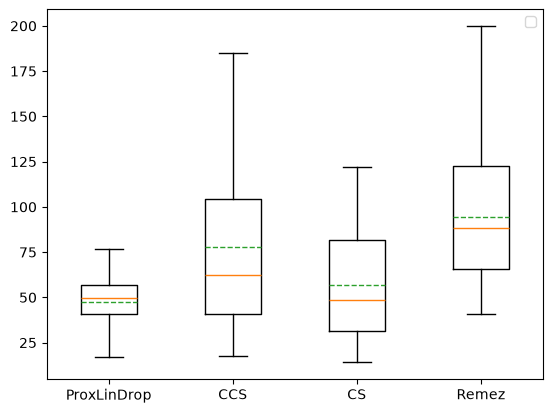

In [6]:
seed=60531
m=10
res1=np.load("exp_lin_dim"+str(m)+"_seed"+str(seed)+".npy")
tables(res1)

In [2]:
A=np.zeros((4,2))
b=[0,2,0,2]
A[0][0]=A[2][0]=-1
A[1][1]=A[3][1]=1
x0=np.array([1,-1])
y0=np.zeros((4,))

Q=np.array([[1,0.5],[0.5,1]])



y0=np.zeros((4,2))
x0=np.array([1,1])

Y=[(generic_fun,[norm2,[i]]) for i  in range(4)]
def gcps(x,y):
    cs=[(A[i]+0.2*y[i]).T@x-b[i] for i in range(4)]
    return cs
vf_maximum_concave(x0,y0,gcps,Y)

(np.float64(-0.7171569594368015),
 array([[0.7071076, 0.7071076],
        [0.       , 0.       ],
        [0.       , 0.       ],
        [0.       , 0.       ]]))

In [3]:
def fcp(x):
    return -cp.sum(x)
def f(x):
    return -np.sum(x)
def df(x):
    return -np.ones(2)
A=np.array([[-1,0],[0,-1],[1,0],[0,1]])
b=[0,0,1,1]
X=[(linear,[A,[2,2,2,2]])]
#X=[]
Y=[(generic_fun,[norm2,[i]]) for i  in range(4)]
def gcp(x,y):
    return (A+0.2*y)@x-b
def g(x,y):
    return np.max((A+0.2*y)@x-b)
def dg(x,y):
    imax=np.argmax([(A+0.2*y)[i]@x -b[i] for i in range(4) ])
    return (A+0.2*y)[imax]
def gcps(x,y):
     #print(y)
    cs=[(A[i]+0.2*y[i]).T@x-b[i] for i in range(4)]
    return cs
y0=[np.zeros((4,2))]
x0=np.array([1,1])

In [4]:
res1=AlgPenDisc(x0,y0,fcp,gcp,g,X,Y,concave=True,gcps=gcps)

Time 0.19426488876342773
Time upper problem 0.020829439163208008
Time lower problem 0.17343544960021973
Feasibility 2.03001571552619e-07
Final rho 4
Rho increases 2
Optimal value -1.5590407616227855
Value function call 4


In [5]:
res1=AlgProxPen(x0,y0,fcp,gcp,g,X,Y,concave=True,gcps=gcps,rho=1,f=f,df=df,dg=dg,gamma=1)

Time 0.22896146774291992
Time upper problem 0.04260849952697754
Time lower problem 0.18635296821594238
Feasibility 5.316952411682507e-08
Final rho 4
Rho increases 2
Optimal value -1.5590409976813127
Value function call 5


In [6]:
res1=AlgBF(x0,y0,fcp,gcp,g,X,Y,concave=True,gcps=gcps)

Time 0.17202305793762207
Time upper problem 0.030780792236328125
Time lower problem 0.14124226570129395
Feasibility 2.0386224908186534e-07
Optimal value -1.559040762864484
Value function call 4


In [7]:
res1=AlgMePa(x0,y0,fcp,gcp,g,X,Y,concave=True,gcps=gcps)

Time 0.41853880882263184
Time upper problem 0.08270120620727539
Time lower problem 0.33480238914489746
Feasibility -0.0002764681734431784
Optimal value -1.5590291256703266
Optimality cuts 6
Feasibility cuts 4
Value function calls 10


In [78]:
n=10
c=np.random.rand(n)*10-5
def fcp(x):
    return c.T@x
def f(x):
    return c.T@x
def df(x):
    return c
A=np.zeros((2*n,n))
A[:n,:n]=-np.eye(n)
A[n:,:n]=np.eye(n)
b=np.random.rand(2*n)
X=[(linear,[A,2*np.ones(2*n)])]

Y=[(generic_fun,[norm2,[i]]) for i  in range(2*n)]

delta=np.random.rand()*0.2+0.1
def gcp(x,y):
    return (A+delta*y)@x-b
def g(x,y):
    return np.max((A+delta*y)@x-b)
def dg(x,y):
    imax=np.argmax([(A+delta*y)[i]@x -b[i] for i in range(2*n) ])
    return (A+delta*y)[imax]
def gcps(x,y):
     #print(y)
    cs=[(A[i]+delta*y[i]).T@x-b[i] for i in range(2*n)]
    return cs
y0=[np.zeros((2*n,n))]
x0=np.ones(n)

In [79]:
#res1=AlgPenDisc(x0,y0,fcp,gcp,g,X,Y,concave=True,gcps=gcps)

In [80]:
res1=AlgProxPen(x0,y0,fcp,gcp,g,X,Y,concave=True,gcps=gcps,rho=1,f=f,df=df,dg=dg,gamma=1)

Time 68.45736861228943
Time upper problem 12.366262197494507
Time lower problem 56.09110641479492
Feasibility 2.293170042950987e-05
Final rho 128
Rho increases 7
Optimal value -5.04746518001056
Value function call 78


In [81]:
res1=AlgBF(x0,y0,fcp,gcp,g,X,Y,concave=True,gcps=gcps)

Time 106.248206615448
Time upper problem 56.98449754714966
Time lower problem 49.26327180862427
Feasibility 0.0008964728329687449
Optimal value -5.0739628762327795
Value function call 68


In [22]:
n=10
c=np.random.rand(n)*2-1
q=np.random.rand(n,n)
Q=q.T@q+0.1*np.eye(n)
def fcp(x):
    return x.T@Q@x + c.T@x

def df(x):
    return 2*Q@x + c
A=np.zeros((2*n,n))
A[:n,:n]=np.eye(n)
A[n:,:n]=-np.eye(n)
b=np.ones(2*n)

X=[(linear,[A,2*b])]
b[n:]=np.random.rand(n)
b[:n]=np.random.rand(n)+2
Y=[(generic_fun,[norm2,[i]]) for i  in range(2*n)]
delta=0.2
def norm2(y,param):
    j=param[0]
    return cp.norm(y[j],2)-1
    
def dg(x,y):
    imax=np.argmax([(A+0.2*y)[i]@x -b[i] for i in range(2*n) ])
    return (A+0.2*y)[imax]
    
def gcp(x,y):
     return (A+delta*y)@x-b
def g(x,y):
     #print(np.linalg.norm(x,2))
     return np.max((A+delta*y)@x-b)
def gcps(x,y):
     #print(y)
     cs=[(A[i]+delta*y[i]).T@x-b[i] for i in range(2*n)]
     return cs
y0=[np.zeros((2*n,n))]
x0=np.random.rand(n)

In [23]:
res1=AlgProxPen(x0,y0,fcp,gcp,g,X,Y,concave=True,gcps=gcps,rho=1,f=fcp,df=df,dg=dg,gamma=1)


KeyboardInterrupt: 

In [19]:
res1=AlgBF(x0,y0,fcp,gcp,g,X,Y,concave=True,gcps=gcps)

Time 6.436966419219971
Time upper problem 0.0916905403137207
Time lower problem 6.34527587890625
Feasibility 0.000575764070509837
Optimal value -0.5712812572159355
Value function call 9


In [10]:
n=20
m=5
c=np.random.rand(n)*2-1
q=np.random.rand(n,n)
Q=q.T@q+0.1*np.eye(n)
def fcp(x):
    return x.T@Q@x + c.T@x

def df(x):
    return 2*Q@x + c

X=[]
A=np.random.rand(m,n)*10-5
b=np.random.rand(m)+1
Y=[(generic_fun,[norm2,[i]]) for i  in range(m)]
delta=0.2
def norm2(y,param):
    j=param[0]
    return cp.norm(y[j],2)-1
    
def dg(x,y):
    imax=np.argmax([(A+0.2*y)[i]@x -b[i] for i in range(m) ])
    return (A+0.2*y)[imax]
    
def gcp(x,y):
     return (A+delta*y)@x-b
def g(x,y):
     #print(np.linalg.norm(x,2))
     return np.max((A+delta*y)@x-b)
def gcps(x,y):
     #print(y)
     cs=[(A[i]+delta*y[i]).T@x-b[i] for i in range(m)]
     return cs
y0=[np.zeros([m,n])]
x0=np.random.rand(n)

In [11]:
res1=AlgPenDisc(x0,y0,fcp,gcp,g,X,Y,f=fcp,df=df,dg=dg,concave=True,gcps=gcps,rho=1)



508.75755505941373
Number of iter 191
Number of iter 176
Number of iter 119
Number of iter 176
Number of iter 109
Number of iter 90
Number of iter 164
Number of iter 95
Number of iter 78
Number of iter 163
Number of iter 158
Number of iter 88
1
Number of iter 278
Number of iter 214
Number of iter 124
Number of iter 96
Number of iter 103
Number of iter 86
Number of iter 173
Number of iter 180
Number of iter 98
Number of iter 214
Number of iter 193
Number of iter 109
Number of iter 109
Number of iter 84
Number of iter 221
Number of iter 195
Number of iter 110
Number of iter 178
Number of iter 185
Number of iter 104
Number of iter 219
Number of iter 196
Number of iter 112
Number of iter 132
Number of iter 85
Number of iter 219
Number of iter 196
Number of iter 111
Number of iter 179
Number of iter 185
Number of iter 104
Number of iter 219
Number of iter 196
Number of iter 112
Number of iter 132
Number of iter 85
Number of iter 220
Number of iter 196
Number of iter 112
Number of iter 179
N

In [12]:
res1=AlgBF(x0,y0,fcp,gcp,g,X,Y,concave=True,gcps=gcps)

Time 0.21274089813232422
Time upper problem 0.03165245056152344
Time lower problem 0.18108844757080078
Feasibility 0.0006013441299872468
Optimal value -4.34061491505204
Value function call 3


In [41]:
n=100

c=np.random.rand(n)*2-1
q=np.random.rand(n,n)
Q=q.T@q
def fcp(x):
    return x.T@Q@x + c.T@x
def norm2_1(y,param):
    return cp.norm(y)-1

A=-np.eye(n)
b=np.zeros(n)
X=[(linear,[A,b])]
Y=[(generic_fun,[norm2_1,[]]),(linear,[A,b])]
delta=0.2
def gcp(x,y):
     return cp.sum([y[i]*(cp.exp(x[i]*i)) for i in range(n)])
def g(x,y):
     return np.sum([y[i]*(np.exp(x[i]*i)) for i in range(n)])
def gcps(x,y):
     #print(y)
     cs=[cp.sum([y[i]*(np.exp(x[i]*i)) for i in range(n)])]
     return cs
y0=[np.zeros(n)]
x0=np.random.rand(n)

In [42]:
res1=AlgPenDisc(x0,y0,fcp,gcp,g,X,Y,concave=True,gcps=gcps,rho=1)
res1=AlgBF(x0,y0,fcp,gcp,g,X,Y,concave=True,gcps=gcps)

TypeError: 'NoneType' object is not subscriptable

In [31]:
n=5
c=np.random.rand(n)*20-10
def fcp(x):
    return cp.norm(x-c,1)
A=np.zeros((2*n,n))
A[:n,:n]=np.eye(n)
A[n:,:n]=-np.eye(n)
b=np.ones(2*n)
b[n:]=np.zeros(n)
X=[(linear,[A,2*b])]
Y=[(generic_fun,[norm2,[i]]) for i  in range(2*n)]
delta=0.2
def norm2(y,param):
    j=param[0]
    return cp.norm(y[j],2)-1
    
def gcp(x,y):
     return (A+delta*y)@x-b
def g(x,y):
     return (A+delta*y)@x-b
def gcps(x,y):
     #print(y)
     cs=[(A[i]+delta*y[i]).T@x-b[i] for i in range(2*n)]
     return cs
y0=[np.zeros((2*n,n))]
x0=np.random.rand(n)